In [2]:
import pandas as pd

In [3]:
train_df = pd.read_csv("data/processed/train_20k.csv")
val_df = pd.read_csv("data/processed/validation_10k.csv")
test_df = pd.read_csv("data/processed/test_10k.csv")

In [4]:
print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

Train: (20000, 7)
Validation: (10000, 16)
Test: (10000, 16)


In [5]:
#prepare text and labels
# we will use clean_title first 

#for train data
X_train = train_df["clean_title"]
y_train = train_df["2_way_label"]

#for val data 

X_val = val_df["clean_title"]
y_val = val_df["2_way_label"]

# for tesst data
X_test = test_df["clean_title"]
y_test = test_df["2_way_label"]

print(X_train.head())
print(y_train.head())

0                                  this photo of putin
1    the name of lenin shines on our victories sovi...
2             i dont think hes the only one alone here
3    this cat in a costume talking to a goku cosplayer
4    he survived floor plunge and now walks for cha...
Name: clean_title, dtype: str
0    1
1    0
2    0
3    0
4    1
Name: 2_way_label, dtype: int64


In [6]:
# we use the NLP concept here (Natural language processing)
# Convert text to TF-IDF
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features = 10000,
    stop_words = "english",
    ngram_range = (1,2)
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_val_tfidf = tfidf.transform(X_val)
X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)

# 20000 → number of training examples
# 10000 → number of TF-IDF features

Training TF-IDF shape: (20000, 10000)


In [7]:
#train the Logistic regression
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    max_iter = 1000,
    random_state = 42
)

model.fit(X_train_tfidf , y_train)
print("model , training completed")

model , training completed


In [8]:
#we use random forest there 
from sklearn.ensemble import RandomForestClassifier

models = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    random_state=42,
   
)

models.fit(X_train_tfidf , y_train)
print("model training completed")

model training completed


In [10]:
from sklearn.metrics import accuracy_score
y_pred = models.predict(X_test_tfidf)
print("Accuracy :", accuracy_score(y_test, y_pred))

Accuracy : 0.74


In [11]:
# we use linear SVC model 
from sklearn.svm import LinearSVC
model = LinearSVC(
    C=1.0,
    random_state=42,
    max_iter=2000
)

# Train the model
model.fit(X_train_tfidf, y_train)

y_pred = models.predict(X_test_tfidf)
print("Accuracy :", accuracy_score(y_test, y_pred))

Accuracy : 0.74


In [7]:
# Evalute the metrics
from sklearn.metrics import accuracy_score ,  precision_score , recall_score , f1_score , classification_report

y_pred = model.predict(X_test_tfidf)
print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("F1 Score :", f1_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy : 0.7547
Precision: 0.7548529117470483
Recall   : 0.7544
F1 Score : 0.7546263879163749

Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.76      0.75      5000
           1       0.75      0.75      0.75      5000

    accuracy                           0.75     10000
   macro avg       0.75      0.75      0.75     10000
weighted avg       0.75      0.75      0.75     10000



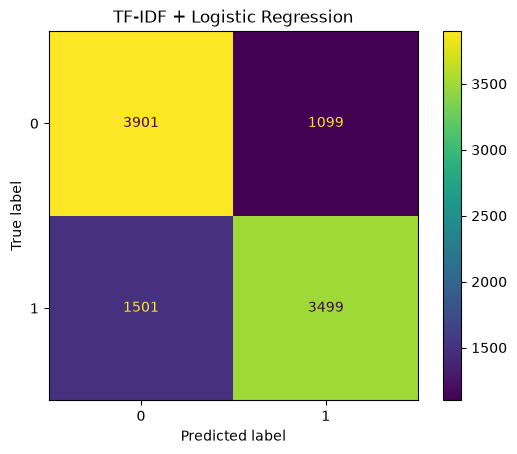

In [12]:
#confusion matrix

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm
)

disp.plot()
plt.title("TF-IDF + Logistic Regression")
plt.show()

In [9]:
import torch
import transformers

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu128
CUDA available: True
GPU: NVIDIA GeForce RTX 3050 Laptop GPU


In [13]:
import torch

print("GPU:", torch.cuda.get_device_name(0))
print("VRAM:", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2), "GB")

GPU: NVIDIA GeForce RTX 3050 Laptop GPU
VRAM: 4.0 GB


In [14]:
import transformers

print("Transformers:", transformers.__version__)

Transformers: 5.18.0


In [15]:
!pip install -U transformers datasets accelerate sentencepiece

   ---------------------------------------- 0.0/604.4 kB ? eta -:--:--
   ----------------- ---------------------- 262.1/604.4 kB ? eta -:--:--
   ---------------------------------------- 604.4/604.4 kB 2.4 MB/s  0:00:00
   ---------------------------------------- 0.0/1.2 MB ? eta -:--:--
   ---------------- ----------------------- 0.5/1.2 MB 3.4 MB/s eta 0:00:01
   ---------------------------------------- 1.2/1.2 MB 3.1 MB/s  0:00:00
   ---------------------------------------- 0.0/27.9 MB ? eta -:--:--
    --------------------------------------- 0.5/27.9 MB 2.8 MB/s eta 0:00:10
   - -------------------------------------- 1.0/27.9 MB 2.4 MB/s eta 0:00:12
   -- ------------------------------------- 1.8/27.9 MB 3.0 MB/s eta 0:00:09
   --- ------------------------------------ 2.6/27.9 MB 3.2 MB/s eta 0:00:08
   ---- ----------------------------------- 3.4/27.9 MB 3.4 MB/s eta 0:00:08
   ------ --------------------------------- 4.5/27.9 MB 3.6 MB/s eta 0:00:07
   ------- ------------------